In [206]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

In [164]:
df = pd.read_csv("/content/drive/MyDrive/ICT AI ML/dataset/heart_disease.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [165]:
print("Shape:", df.shape)

Shape: (1025, 14)


In [166]:
df.duplicated().sum()

np.int64(723)

In [167]:
df=df.drop_duplicates()

In [168]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


In [169]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [170]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [171]:
categorical_columns = ["sex","cp","fbs","restecg","exang","slope","ca","thal","target"]
for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 sex
sex
1    206
0     96
Name: count, dtype: int64

 cp
cp
0    143
2     86
1     50
3     23
Name: count, dtype: int64

 fbs
fbs
0    257
1     45
Name: count, dtype: int64

 restecg
restecg
1    151
0    147
2      4
Name: count, dtype: int64

 exang
exang
0    203
1     99
Name: count, dtype: int64

 slope
slope
2    141
1    140
0     21
Name: count, dtype: int64

 ca
ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

 thal
thal
2    165
3    117
1     18
0      2
Name: count, dtype: int64

 target
target
1    164
0    138
Name: count, dtype: int64


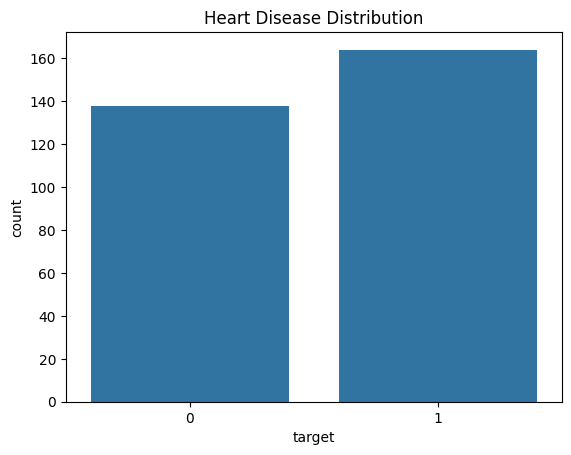

In [172]:
sns.countplot(x="target", data=df)
plt.title("Heart Disease Distribution")
plt.show()

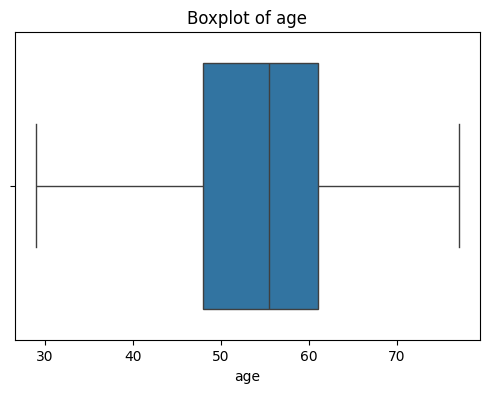

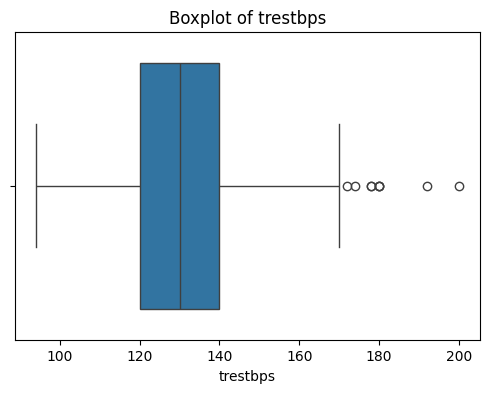

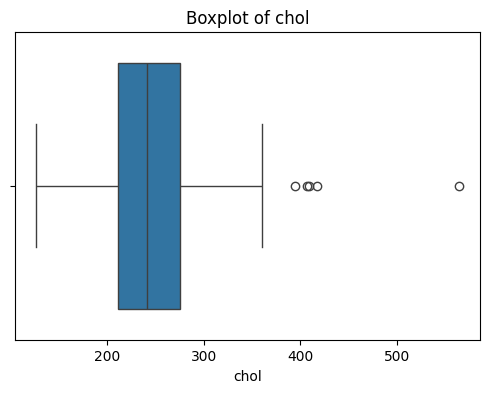

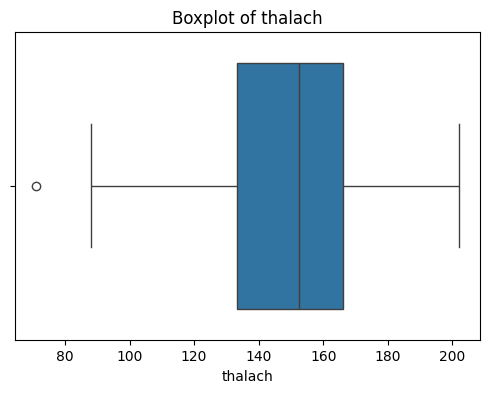

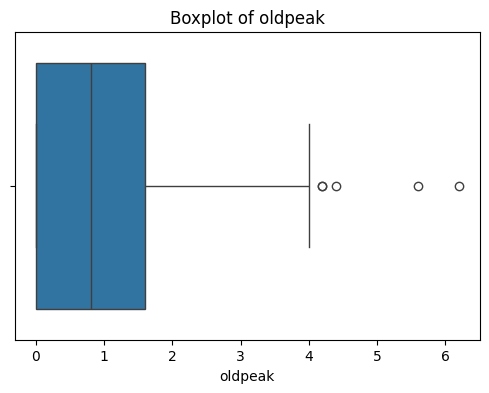

In [173]:
numerical_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

for col in numerical_columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [174]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]
    return outliers

In [175]:
for col in numerical_columns:
    outliers = detect_outliers_iqr(df, col)
    print(col, ":", len(outliers), "outliers")

age : 0 outliers
trestbps : 9 outliers
chol : 5 outliers
thalach : 1 outliers
oldpeak : 5 outliers


In [176]:
correlation = df.corr(numeric_only=True)["chol"].sort_values(ascending=False)
print(correlation)

chol        1.000000
age         0.207216
trestbps    0.125256
thal        0.096810
ca          0.086878
exang       0.064099
oldpeak     0.050086
fbs         0.011428
slope       0.000417
thalach    -0.005308
cp         -0.072682
target     -0.081437
restecg    -0.147602
sex        -0.195571
Name: chol, dtype: float64


In [177]:
selected_reg_features = correlation[
    correlation.abs() >= 0.1
].index.tolist()

selected_reg_features.remove("chol")

print("Selected Regression Features:")
print(selected_reg_features)

Selected Regression Features:
['age', 'trestbps', 'restecg', 'sex']


In [178]:
X_reg = df[selected_reg_features]
y_reg = df["chol"]

In [179]:
X_reg = pd.get_dummies(
    X_reg,
    columns=["restecg"],
    drop_first=True,
    dtype=int
)

In [180]:
from sklearn.model_selection import train_test_split
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

In [181]:
from sklearn.preprocessing import StandardScaler
scaler_reg = StandardScaler()
X_reg_train_scaled = scaler_reg.fit_transform(X_reg_train)
X_reg_test_scaled = scaler_reg.transform(X_reg_test)

In [182]:
linear_model = LinearRegression()
linear_model.fit(
    X_reg_train_scaled,
    y_reg_train
)
linear_pred = linear_model.predict(X_reg_test_scaled)

In [183]:
svm_model = SVR()
svm_model.fit(
    X_reg_train_scaled,
    y_reg_train
)
svm_pred = svm_model.predict(X_reg_test_scaled)

In [184]:
rf_reg_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_reg_model.fit(
    X_reg_train,
    y_reg_train
)
rf_reg_pred = rf_reg_model.predict(X_reg_test)

In [185]:
def evaluate_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, r2

In [186]:
linear_results = evaluate_regression(
    y_reg_test,
    linear_pred
)
svm_results = evaluate_regression(
    y_reg_test,
    svm_pred
)
rf_reg_results = evaluate_regression(
    y_reg_test,
    rf_reg_pred
)

In [187]:
regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "SVM",
        "Random Forest"
    ],
    "MAE": [
        linear_results[0],
        svm_results[0],
        rf_reg_results[0]
    ],
    "MSE": [
        linear_results[1],
        svm_results[1],
        rf_reg_results[1]
    ],
    "R2": [
        linear_results[2],
        svm_results[2],
        rf_reg_results[2]
    ]
})
regression_results

,Model,MAE,MSE,R2
0,Linear Regression,34.488106,1937.113913,-0.056014
1,SVM,31.989470,1772.519091,0.033715
2,Random Forest,40.015340,2735.929269,-0.491486


In [188]:
best_regression_model = regression_results.loc[
    regression_results["R2"].idxmax()
]
print("Best Regression Model:")
print(best_regression_model)

Best Regression Model:
Model            SVM
MAE         31.98947
MSE      1772.519091
R2          0.033715
Name: 1, dtype: object


In [189]:
correlation_target = df.corr(numeric_only=True)["target"].sort_values(
    ascending=False
)
print(correlation_target)

target      1.000000
cp          0.432080
thalach     0.419955
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.081437
trestbps   -0.146269
age        -0.221476
sex        -0.283609
thal       -0.343101
ca         -0.408992
oldpeak    -0.429146
exang      -0.435601
Name: target, dtype: float64


In [190]:
selected_clf_features = correlation_target[
    correlation_target.abs() >= 0.1
].index.tolist()

selected_clf_features.remove("target")

print("Selected Classification Features:")
print(selected_clf_features)

Selected Classification Features:
['cp', 'thalach', 'slope', 'restecg', 'trestbps', 'age', 'sex', 'thal', 'ca', 'oldpeak', 'exang']


In [191]:
X_clf = df[selected_clf_features]
y_clf = df["target"]

In [192]:
X_clf = pd.get_dummies(
    X_clf,
    columns=["cp", "restecg", "thal"],
    drop_first=True,
    dtype=int
)

In [193]:
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf,
    y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

In [194]:
scaler_clf = StandardScaler()
X_clf_train_scaled = scaler_clf.fit_transform(X_clf_train)
X_clf_test_scaled = scaler_clf.transform(X_clf_test)

In [195]:
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)
logistic_model.fit(
    X_clf_train_scaled,
    y_clf_train
)
logistic_pred = logistic_model.predict(X_clf_test_scaled)

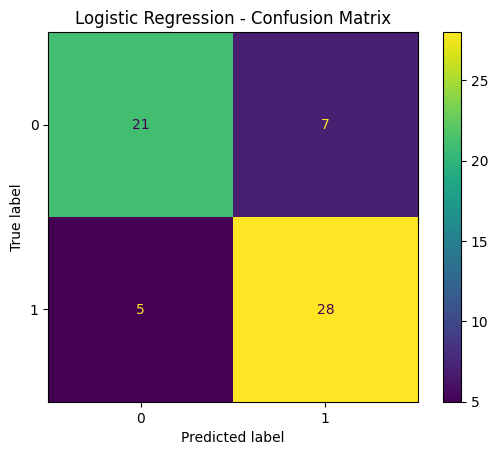

In [207]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_clf_test,
    logistic_pred
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [196]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(
    X_clf_train_scaled,
    y_clf_train
)
knn_pred = knn_model.predict(X_clf_test_scaled)

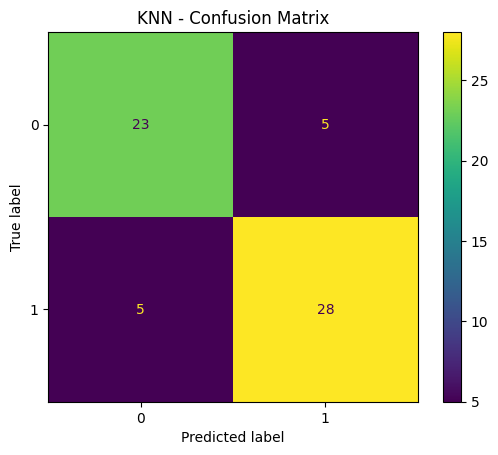

In [208]:
ConfusionMatrixDisplay.from_predictions(
    y_clf_test,
    knn_pred
)

plt.title("KNN - Confusion Matrix")
plt.show()

In [197]:
rf_clf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_clf_model.fit(
    X_clf_train,
    y_clf_train
)
rf_clf_pred = rf_clf_model.predict(X_clf_test)

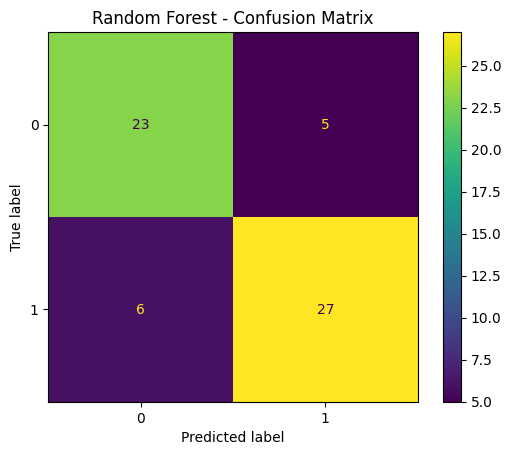

In [209]:
ConfusionMatrixDisplay.from_predictions(
    y_clf_test,
    rf_clf_pred
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [198]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [199]:
def evaluate_classification(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    return accuracy, precision, recall, f1

In [200]:
logistic_results = evaluate_classification(
    y_clf_test,
    logistic_pred
)
knn_results = evaluate_classification(
    y_clf_test,
    knn_pred
)
rf_clf_results = evaluate_classification(
    y_clf_test,
    rf_clf_pred
)

In [201]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_results[0],
        knn_results[0],
        rf_clf_results[0]
    ],
    "Precision": [
        logistic_results[1],
        knn_results[1],
        rf_clf_results[1]
    ],
    "Recall": [
        logistic_results[2],
        knn_results[2],
        rf_clf_results[2]
    ],
    "F1-Score": [
        logistic_results[3],
        knn_results[3],
        rf_clf_results[3]
    ]
})

classification_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.803279,0.800000,0.848485,0.823529
1,KNN,0.836066,0.848485,0.848485,0.848485
2,Random Forest,0.819672,0.843750,0.818182,0.830769


In [202]:
best_classification_model = classification_results.loc[
    classification_results["Recall"].idxmax()
]

print("Best Classification Model:")
print(best_classification_model)

Best Classification Model:
Model        Logistic Regression
Accuracy                0.803279
Precision                    0.8
Recall                  0.848485
F1-Score                0.823529
Name: 0, dtype: object


In [203]:
print("===== REGRESSION RESULTS =====")
display(regression_results)

print("\n===== CLASSIFICATION RESULTS =====")
display(classification_results)

===== REGRESSION RESULTS =====


,Model,MAE,MSE,R2
0,Linear Regression,34.488106,1937.113913,-0.056014
1,SVM,31.989470,1772.519091,0.033715
2,Random Forest,40.015340,2735.929269,-0.491486



===== CLASSIFICATION RESULTS =====


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.803279,0.800000,0.848485,0.823529
1,KNN,0.836066,0.848485,0.848485,0.848485
2,Random Forest,0.819672,0.843750,0.818182,0.830769


In [204]:
print(
    "Best Regression Model:",
    regression_results.loc[
        regression_results["R2"].idxmax(),
        "Model"
    ]
)

print(
    "Best Classification Model:",
    classification_results.loc[
        classification_results["Recall"].idxmax(),
        "Model"
    ]
)

Best Regression Model: SVM
Best Classification Model: Logistic Regression
